# Community Detection and Sector Comparison

Reuses **Brandon’s prototype settings**: 60-day correlation window ending **2008-10-15**, absolute-correlation threshold **0.55**, undirected/unweighted graph, self-loops and isolates removed. Uses the shared `src.windows.correlation_at` function and processed returns. Run all cells from a checkout of RGBFS. Sector comparison needs a ticker-to-sector mapping file; if none is available, the notebook explains how to supply one rather than inventing labels.

In [24]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

# Works when the notebook is opened from either RGBFS/ or RGBFS/notebooks/.
root = Path.cwd().resolve()
if not (root / 'src').exists() and (root.parent / 'src').exists():
    root = root.parent
if not (root / 'src').exists():
    raise FileNotFoundError('Open this notebook from the RGBFS repository root or notebooks/ directory.')
sys.path.insert(0, str(root))
from src.windows import correlation_at
try:
    from src import returns as rt
except ImportError:
    rt = None

TARGET_DATE = '2008-10-15'
WINDOW = 60
THRESHOLD = 0.55
OUTPUT_DIR = root / 'notebooks' / 'outputs' / 'grace_week2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Repository:', root)
print('Outputs:', OUTPUT_DIR)

Repository: C:\Users\dayan\Downloads\RGBFS
Outputs: C:\Users\dayan\Downloads\RGBFS\notebooks\outputs\grace_week2


## 1. Load the same processed returns as Brandon

In [25]:
returns_path = root / 'data' / 'processed' / 'returns_daily.parquet'
if rt is not None and hasattr(rt, 'load_returns'):
    try:
        rets = rt.load_returns()
        print('Loaded using src.returns.load_returns()')
    except Exception as exc:
        if not returns_path.exists():
            raise RuntimeError('Shared returns loader failed and fallback parquet is missing.') from exc
        print('Shared loader failed; using Brandon’s parquet:', exc)
        rets = pd.read_parquet(returns_path)
else:
    if not returns_path.exists():
        raise FileNotFoundError(f'Missing {returns_path}. Copy the team processed files first.')
    rets = pd.read_parquet(returns_path)

print('Returns shape:', rets.shape)
display(rets.head())

Loaded using src.returns.load_returns()
Returns shape: (5491, 977)


,A,AABA,AAL,AAP,AAPL,ABBV,ABC,ABI,ABKFQ,ABMD,...,XRAY,XRX,XTO,XYL,XYZ,YUM,ZBH,ZBRA,ZION,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2005-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-04,-0.026382,NaN,NaN,NaN,0.010270,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.014732,NaN,NaN,NaN,-0.013242,-0.000378,NaN,-0.013652,NaN
2005-01-05,-0.000430,NaN,NaN,NaN,0.008758,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.019737,NaN,NaN,NaN,-0.002381,-0.007813,NaN,-0.003611,NaN
2005-01-06,-0.021945,NaN,NaN,NaN,0.000775,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.004271,NaN,NaN,NaN,0.011282,0.011558,NaN,0.005737,NaN
2005-01-07,-0.000880,NaN,NaN,NaN,0.072811,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.005515,NaN,NaN,NaN,-0.005578,-0.001758,NaN,-0.024321,NaN


## 2. Reconstruct Brandon’s prototype graph exactly

In [26]:
corr = correlation_at(rets, end=TARGET_DATE, window=WINDOW)
if not isinstance(corr, pd.DataFrame) or corr.empty:
    raise ValueError('correlation_at did not return a nonempty pandas DataFrame.')

def make_graph(corr_matrix, threshold=0.55):
    # Brandon: absolute correlation strictly greater than threshold.
    adjacency = (corr_matrix.abs() > threshold).astype(int)
    graph = nx.from_pandas_adjacency(adjacency)
    graph.remove_edges_from(nx.selfloop_edges(graph))
    graph.remove_nodes_from(list(nx.isolates(graph)))
    return graph

G = make_graph(corr, THRESHOLD)
if G.number_of_edges() == 0:
    raise ValueError('No edges at this threshold; try a lower threshold.')
print('Window ending:', TARGET_DATE, '| days:', WINDOW, '| threshold:', THRESHOLD)
print('Nodes:', G.number_of_nodes(), 'Edges:', G.number_of_edges())
print('Density:', round(nx.density(G), 4))

Window ending: 2008-10-15 | days: 60 | threshold: 0.55
Nodes: 296 Edges: 27383
Density: 0.6272


## 3. Detect communities (greedy modularity)

### Interpretation — Correlation network construction

For the 60-trading-day window ending **October 15, 2008**, the graph contains **296 stocks and 27,383 edges** at an absolute-correlation threshold of **0.55**. Its density is **0.6272**, meaning about 62.7% of possible stock pairs among the retained nodes are connected. This indicates a relatively dense correlation network in the selected crisis-period window. Because the graph uses **absolute** correlations, an edge can represent either a strong positive or a strong negative correlation; it does not automatically mean that the two stocks moved in the same direction. Isolated stocks were excluded under Brandon's graph construction rule.

In [27]:
from networkx.algorithms.community import greedy_modularity_communities, modularity

communities = list(greedy_modularity_communities(G))
community_of = {ticker: i + 1 for i, group in enumerate(communities) for ticker in group}
community_df = pd.DataFrame({'ticker': list(G.nodes())})
community_df['community'] = community_df['ticker'].map(community_of)
community_df = community_df.sort_values(['community', 'ticker']).reset_index(drop=True)

print('Communities:', len(communities))
print('Modularity:', round(modularity(G, communities), 4))
display(community_df.groupby('community').size().rename('stocks').reset_index())
display(community_df.head(25))
community_df.to_csv(OUTPUT_DIR / 'community_membership.csv', index=False)

Communities: 2
Modularity: 0.0964


,community,stocks
0,1,160
1,2,136


,ticker,community
0,A,1
1,ABT,1
2,ADI,1
3,ADM,1
4,ADP,1
5,ADSK,1
6,AEE,1
7,AEP,1
8,AES,1
9,AIZ,1


## 4. Visualize the network with community colors

### Interpretation — Community detection

Greedy modularity community detection identifies **two communities**, containing **160** and **136** stocks. The standard modularity score is **0.0964**. This relatively low score indicates that the observed division has limited separation between within-community and between-community links. The algorithm found structure in the network, but the communities are not sharply isolated. These are **correlation-based groups**, not official industry classifications.

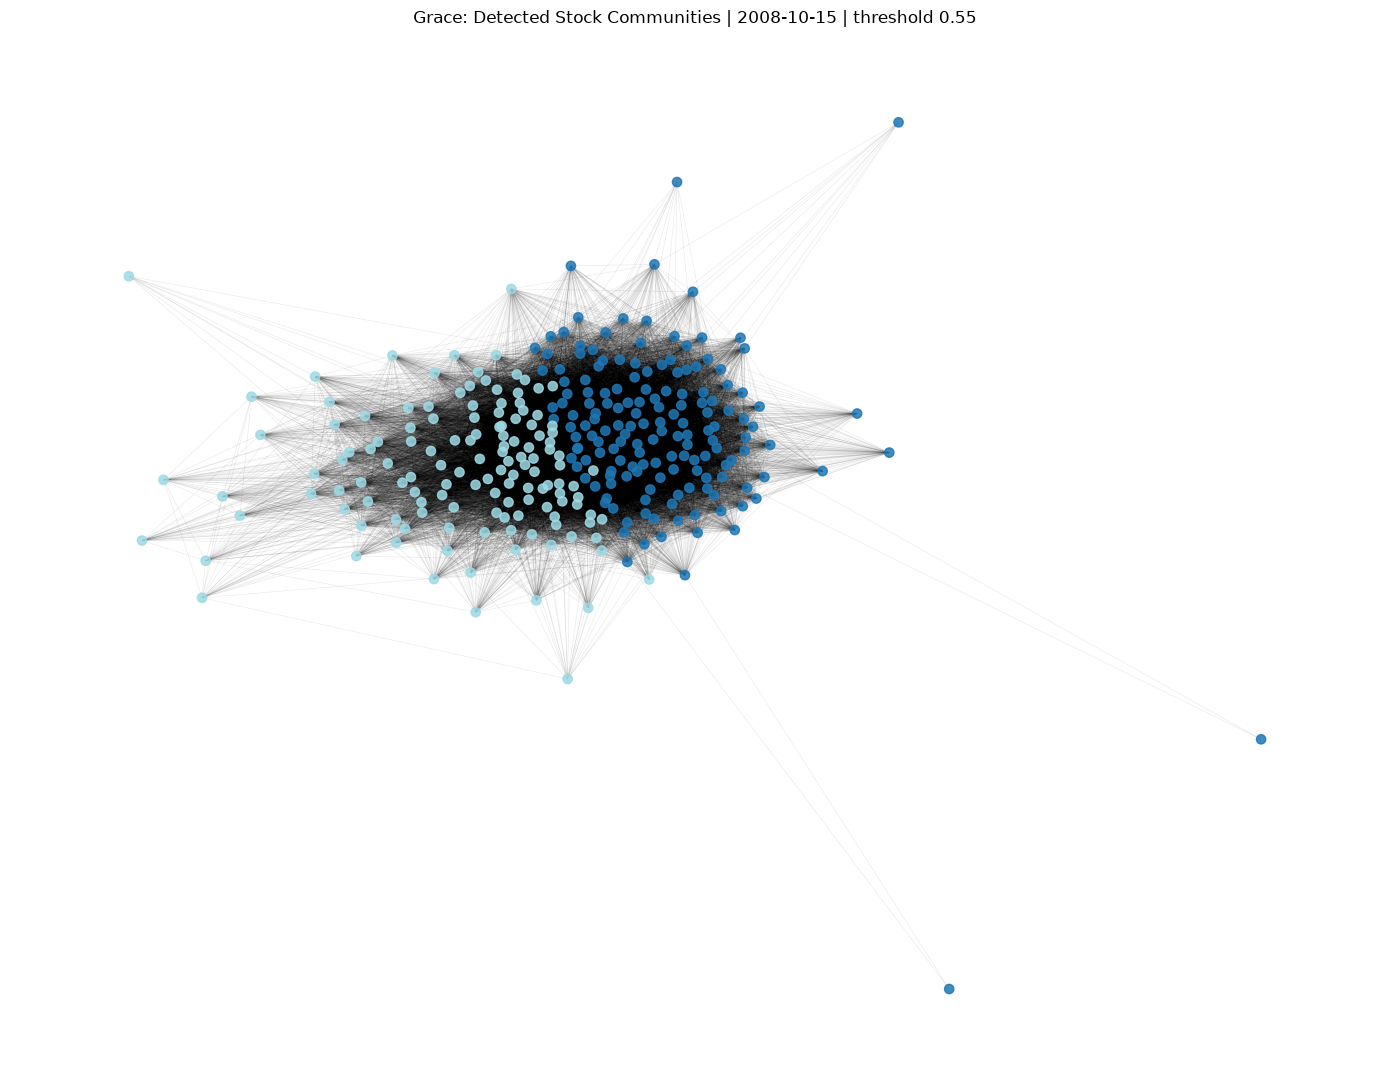

In [28]:
fig, ax = plt.subplots(figsize=(14, 11))
pos = nx.spring_layout(G, seed=42, k=0.15)
colors = [community_of[node] for node in G.nodes()]
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.08, width=0.5)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, cmap=plt.cm.tab20,
                       node_size=45, alpha=0.85)
ax.set_title(f'Grace: Detected Stock Communities | {TARGET_DATE} | threshold {THRESHOLD}')
ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'community_network.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Compare detected communities with official sectors

### What data is used in this analysis?

The notebook uses **two different types of data**, which serve different purposes:

| Data | Expected location | What it contains | How it is used |
|---|---|---|---|
| Daily stock returns | `data/processed/returns_daily.parquet` (loaded through `src.returns.load_returns()`) | Trading dates and daily returns for stock tickers; each stock is a separate series | Calculate the 60-trading-day stock-return correlations and build the network |
| Sector mapping | `data/processed/sector_mapping.csv` | One record per stock with a `ticker` and its `sector` classification | Compare network-detected communities with sector groupings |

**Important distinction:** A stock's **return** is a numerical daily price-change measure used to calculate correlations. Its **sector** is a categorical industry grouping used *after* clustering for comparison; sector labels are **not** inputs to the community-detection algorithm.

For this project, the sector mapping was generated from `components_history.csv` in the public `lawcal/sp500-components-history` dataset. That source includes fields such as `symbol` (stock ticker), `name` (company name), `sector` (sector label), `date_added`, and `date_removed` (membership dates). Records were filtered to stocks listed as members on **October 15, 2008**, and `symbol` was renamed to `ticker`. The resulting mapping contained **361 ticker-sector records**; of the **296 stocks in the correlation network**, **250 matched** the mapping and **46 did not**. The mapping is a **partial, historically filtered lookup**, not a guarantee of complete S&P 500 membership or point-in-time sector accuracy.

The sector values in this particular source are lowercase labels such as `financials`, `health_care`, `information_technology`, and `consumer_discretionary`. The example CSV below uses human-readable labels to illustrate the required columns; **either style can be read**, but use a consistent naming convention throughout the mapping. Some labels (notably `real_estate` and `communication_services`) reflect later GICS structures and should **not** be represented as verified 2008 sector classifications.

### Required sector mapping file format

The sector comparison requires a **CSV file** named `sector_mapping.csv` saved in `RGBFS/data/processed/`. It must contain at least these two columns, spelled exactly as shown:

| Column | Meaning | Example |
|---|---|---|
| `ticker` | Stock symbol matching the returns/network data | `AAPL` |
| `sector` | Sector classification for that stock | `Information Technology` |

Example CSV contents:

```csv
ticker,sector
AAPL,Information Technology
JPM,Financials
BAC,Financials
XOM,Energy
JNJ,Health Care
WMT,Consumer Staples
```

Use **one row per ticker**, with no missing ticker or sector values. Additional columns such as `name` are acceptable. Ticker symbols should match the stock identifiers used in the network. The example rows illustrate the format; they are **not** a complete 2008 sector mapping.

**Historical limitation:** This analysis uses a window ending **October 15, 2008**. Ideally, sector labels should reflect classifications applicable then. If the available mapping uses later GICS classifications, report this as a limitation rather than describing them as verified 2008 labels.

The code below searches for common filenames automatically, including `data/processed/sector_mapping.csv`. You can also set `SECTOR_FILE` explicitly to a different verified CSV path. If no mapping is found, the other analyses can still run, but the sector comparison will remain incomplete.


### Interpretation — Community visualization

The network chart colors nodes according to their detected community. The visualization helps illustrate how the two groups are distributed across the correlation graph, but visual proximity alone should not be interpreted as an industry relationship or as proof of causality. The spring-layout positions are algorithmic and can vary with layout settings.

In [29]:
# Optional: explicitly set to your verified mapping, e.g. root / 'data/processed/sectors_2008.csv'
SECTOR_FILE = None
candidates = [
    root / 'data/processed/sectors_2008.csv',
    root / 'data/processed/sector_mapping.csv',
    root / 'data/processed/sectors.csv',
    root / 'data/raw/sectors.csv',
]
sector_path = Path(SECTOR_FILE) if SECTOR_FILE else next((p for p in candidates if p.exists()), None)
sector_comparison = None
if sector_path is None:
    print('SECTOR COMPARISON PENDING: no sector mapping found.')
    print('Create or locate a verified ticker/sector CSV and set SECTOR_FILE above, then rerun.')
else:
    print('Using sector mapping:', sector_path)
    sector_raw = pd.read_csv(sector_path)
    print('Available columns:', list(sector_raw.columns))
    column_lookup = {str(c).strip().lower(): c for c in sector_raw.columns}
    ticker_col = next((column_lookup[x] for x in ('ticker','symbol','tic') if x in column_lookup), None)
    sector_col = next((column_lookup[x] for x in ('sector','gics_sector','gics sector') if x in column_lookup), None)
    if ticker_col is None or sector_col is None:
        print('Mapping must have ticker/symbol and sector/GICS_sector columns. Set a compatible file.')
    else:
        sectors = sector_raw[[ticker_col, sector_col]].rename(columns={ticker_col:'ticker',sector_col:'sector'}).copy()
        sectors['ticker'] = sectors['ticker'].astype(str).str.strip()
        sectors['sector'] = sectors['sector'].astype('string').str.strip()
        sectors = sectors.dropna(subset=['ticker','sector']).drop_duplicates(subset='ticker')
        sector_comparison = community_df.merge(sectors, on='ticker', how='left')
        matched = sector_comparison['sector'].notna().sum()
        print(f'Sector coverage: {matched}/{len(sector_comparison)} ({matched/len(sector_comparison):.1%})')
        display(pd.crosstab(sector_comparison['community'], sector_comparison['sector'], dropna=False))
        display(sector_comparison.head(25))
        sector_comparison.to_csv(OUTPUT_DIR / 'community_sector_comparison.csv', index=False)
        if matched >= 2:
            from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
            matched_df = sector_comparison.dropna(subset=['sector'])
            print('Adjusted Rand Index:', round(adjusted_rand_score(matched_df['sector'], matched_df['community']), 4))
            print('Normalized Mutual Information:', round(normalized_mutual_info_score(matched_df['sector'], matched_df['community']), 4))
        else:
            print('Too few matched tickers to score sector alignment.')

Using sector mapping: C:\Users\dayan\Downloads\RGBFS\data\processed\sector_mapping.csv
Available columns: ['ticker', 'name', 'sector']
Sector coverage: 250/296 (84.5%)


sector,communication_services,consumer_discretionary,consumer_staples,energy,financials,health_care,industrials,information_technology,materials,real_estate,utilities,<NA>
community,,,,,,,,,,,,
1,5,2,19,13,10,26,16,15,9,1,19,25
2,1,27,5,0,35,2,22,11,3,9,0,21


,ticker,community,sector
0,A,1,health_care
1,ABT,1,health_care
2,ADI,1,information_technology
3,ADM,1,consumer_staples
4,ADP,1,industrials
5,ADSK,1,information_technology
6,AEE,1,utilities
7,AEP,1,utilities
8,AES,1,utilities
9,AIZ,1,financials


Adjusted Rand Index: 0.0787
Normalized Mutual Information: 0.1777


## 6. Parameter sensitivity: correlation threshold

### Interpretation — Comparison with sector classifications

The sector mapping covers **250 of 296 network stocks (84.5%)**, leaving **46 without a matched sector**. The sector composition is mixed rather than one sector per community. In Community 1, the mapped stocks include **26 Health Care**, **19 Consumer Staples**, and **19 Utilities** stocks. Community 2 includes **35 Financials** and **27 Consumer Discretionary** stocks. The **Adjusted Rand Index (ARI) is 0.0787** and **Normalized Mutual Information (NMI) is 0.1777**; both indicate weak agreement between detected communities and sector labels in the matched subset.

**Data provenance and limitations:** The file `data/processed/sector_mapping.csv` was constructed from the public `lawcal/sp500-components-history` repository's `components_history.csv`, filtering membership dates to October 15, 2008. The source's sector labels are **not independently verified as contemporaneous 2008 GICS labels**; for example, `real_estate` and `communication_services` reflect later GICS structures. The comparison is therefore **exploratory**, not a validated historical-sector benchmark. Missing mappings may also affect the comparison. The ARI/NMI values describe association, not causation or a statistical test of crisis effects.

In [30]:
threshold_rows = []
for t in [0.40, 0.50, 0.55, 0.60, 0.70]:
    graph = make_graph(corr, t)
    if graph.number_of_edges() == 0:
        threshold_rows.append({'threshold':t, 'nodes':graph.number_of_nodes(), 'edges':0,
                               'density':np.nan, 'communities':0, 'modularity':np.nan})
        continue
    groups = list(greedy_modularity_communities(graph))
    threshold_rows.append({'threshold':t, 'nodes':graph.number_of_nodes(),
                           'edges':graph.number_of_edges(), 'density':nx.density(graph),
                           'communities':len(groups), 'modularity':modularity(graph, groups)})
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)
threshold_df.to_csv(OUTPUT_DIR / 'threshold_sensitivity.csv', index=False)

,threshold,nodes,edges,density,communities,modularity
0,0.40,296,38662,0.885525,2,0.033721
1,0.50,296,32150,0.736372,2,0.070543
2,0.55,296,27383,0.627187,2,0.096362
3,0.60,296,21634,0.495511,2,0.125049
4,0.70,287,9051,0.220536,4,0.194852


## 7. Parameter sensitivity: greedy modularity resolution

### Interpretation — Correlation threshold sensitivity

Increasing the absolute-correlation threshold makes it harder for stocks to be linked. Network density falls from **0.8855** at threshold **0.40** to **0.2205** at **0.70**. The detected community count stays at **two** for thresholds **0.40–0.60**, then increases to **four** at **0.70**. Standard modularity rises from **0.0337** to **0.1949** across these tests, although the networks are different and modularity values should not be treated as a direct measure of financial performance. At threshold 0.70, the number of retained nodes falls from **296 to 287** because isolates are removed; this affects comparisons across thresholds.

In [31]:
resolution_rows = []
for resolution in [0.5, 1.0, 1.5, 2.0]:
    groups = list(greedy_modularity_communities(G, resolution=resolution))
    resolution_rows.append({'resolution':resolution, 'communities':len(groups),
                            'modularity_standard':modularity(G, groups)})
resolution_df = pd.DataFrame(resolution_rows)
display(resolution_df)
resolution_df.to_csv(OUTPUT_DIR / 'resolution_sensitivity.csv', index=False)

,resolution,communities,modularity_standard
0,0.5,1,0.000000
1,1.0,2,0.096362
2,1.5,119,0.043434
3,2.0,179,0.020562


## 8. Automatic summary to adapt for your Week 2 write-up

### Interpretation — Community detection resolution sensitivity

At resolution **0.5**, the greedy modularity algorithm returns **one community**; at **1.0**, **two**; at **1.5**, **119**; and at **2.0**, **179**. Thus, the resolution parameter strongly influences the granularity of the detected groups. The displayed `modularity_standard` scores are calculated using the **standard modularity definition** for the resulting partitions, not the resolution-adjusted objective optimized at each setting. The baseline resolution of **1.0** is retained for the main sector comparison; the other settings are sensitivity checks.

In [32]:
baseline = threshold_df.loc[np.isclose(threshold_df['threshold'], THRESHOLD)].iloc[0]
print(f'For the 60-day window ending {TARGET_DATE}, Brandon’s graph at threshold {THRESHOLD} '
      f'contained {int(baseline.nodes)} stocks and {int(baseline.edges)} edges. '
      f'Greedy modularity detected {len(communities)} communities '
      f'(modularity {modularity(G, communities):.3f}).')
print('Threshold results:')
print(threshold_df[['threshold','nodes','communities','modularity']].to_string(index=False))
print('Resolution results:')
print(resolution_df.to_string(index=False))
if sector_comparison is None:
    print('Sector alignment: not yet evaluated; verified historical sector mapping is required.')
else:
    print('Sector alignment: inspect the crosstab and scores above; discuss mixed vs sector-pure communities.')
print('Note: community counts across thresholds are affected by dropping isolated stocks.')
print('Saved tables and figure to:', OUTPUT_DIR)

For the 60-day window ending 2008-10-15, Brandon’s graph at threshold 0.55 contained 296 stocks and 27383 edges. Greedy modularity detected 2 communities (modularity 0.096).
Threshold results:
 threshold  nodes  communities  modularity
      0.40    296            2    0.033721
      0.50    296            2    0.070543
      0.55    296            2    0.096362
      0.60    296            2    0.125049
      0.70    287            4    0.194852
Resolution results:
 resolution  communities  modularity_standard
        0.5            1             0.000000
        1.0            2             0.096362
        1.5          119             0.043434
        2.0          179             0.020562
Sector alignment: inspect the crosstab and scores above; discuss mixed vs sector-pure communities.
Note: community counts across thresholds are affected by dropping isolated stocks.
Saved tables and figure to: C:\Users\dayan\Downloads\RGBFS\notebooks\outputs\grace_week2
